# CCF guide

This notebook shows how to compute the cross-correlation function of a set of observations with a binary mask.

Load the necessary modules:

In [10]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import colorcet as cc
import cmocean as cmo

from popurri import spectrum
from popurri import telluricutils
from popurri import plotutils

from raccoon import crosscorr

# mpl.rcdefaults()
plotutils.mpl_custom_basic()
plotutils.mpl_size_same(font_size=18)

# Testing
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Observations

### Read

Load a set of observed spectra into a `spectrum.Spectra` object. It needs a list of the FITS files and the instrument used. Here are going to load a set of spectra observed with CARMENES VIS:

In [11]:
lisfil = [
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20160318T22h26m50s-sci-gtoc-vis_A.fits',
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20160327T21h25m39s-sci-gtoc-vis_A.fits',
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20160411T20h12m48s-sci-gtoc-vis_A.fits',
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20170109T02h38m37s-sci-gtoc-vis_A.fits',
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20170302T20h25m06s-sci-gtoc-vis_A.fits',
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20170412T20h02m25s-sci-gtoc-vis_A.fits',
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20171230T01h42m48s-sci-gtoc-vis_A.fits',
    '/Users/marina/work/data/carmenes_gto/caracal/CARM_VIS/J07446+035/car-20180102T01h14m44s-sci-gtoc-vis_A.fits',
]
inst = 'carmvis'
dirout = './ccf_guide/'

# Read spectrum from filin
lisspec = spectrum.Spectra(lisfil, inst, dirout=dirout)

# Spectra object attributes
# vars(lisspec)  # print attribute name and value
lisspec.__dict__.keys()  # print attribute name

dict_keys(['lisfil', 'lisfil_initial', 'inst', 'obj', 'tag', 'dirout', 'lisspec', 'nobs', 'lisfilname', 'dataspec', 'nord', 'ords', 'ords_real', 'ord_ref', 'pixel_ms', 'npix', 'dataheader', 'bervminobs', 'bervmaxobs', 'bervabsmaxobs', 'bervabsobj', 'dataord', 'Spectrograph'])

### Plot spectra

We can easily check the data we have loaded with `fig_spectra`.

Let's plot a few orders:

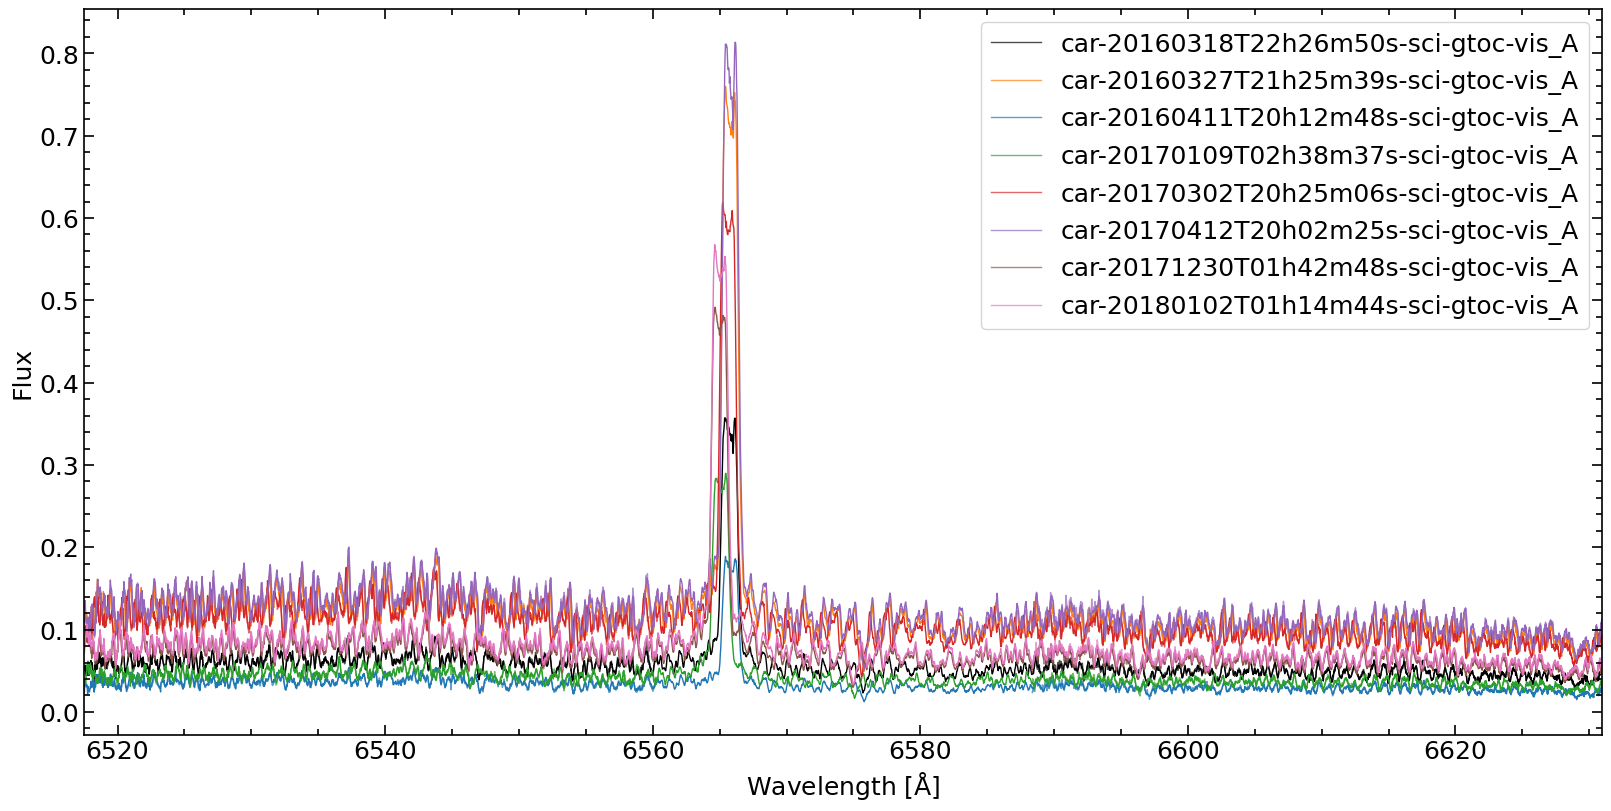

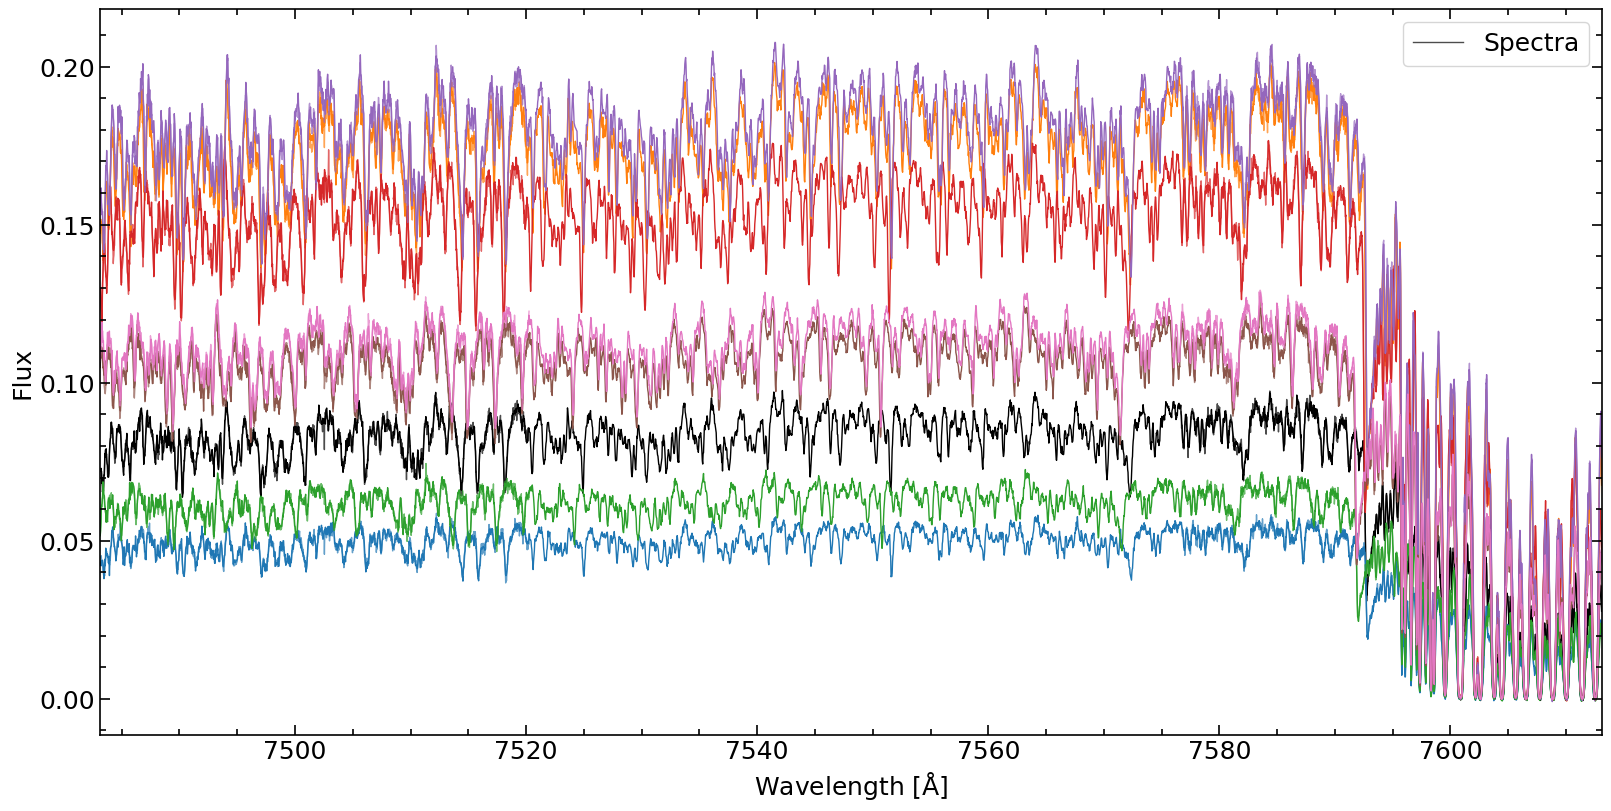

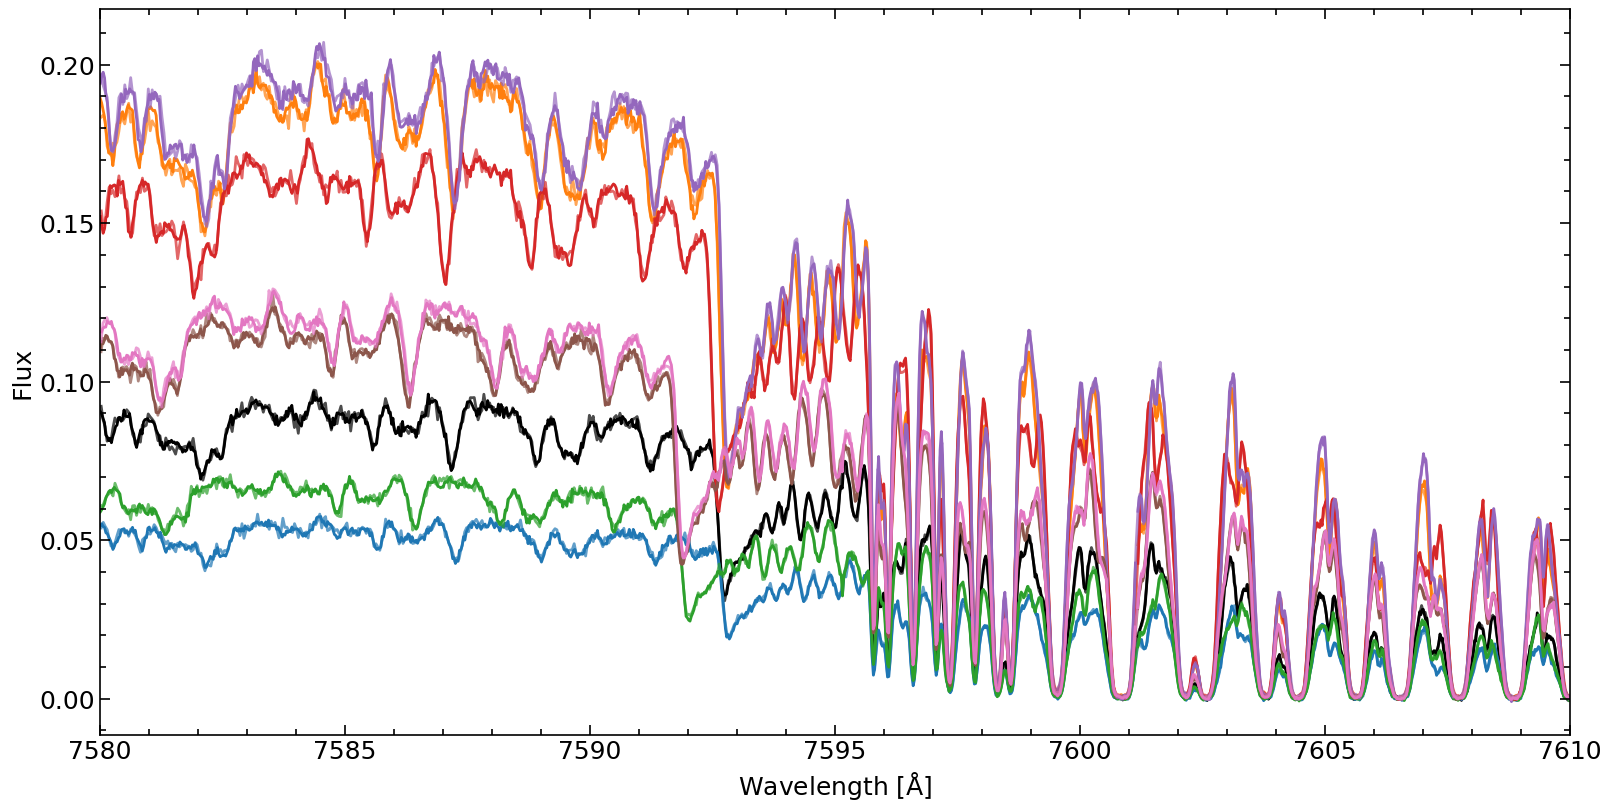

In [12]:
# Plot Halpha order
lisspec.fig_spectra(sh=True, sv=False, ords=np.arange(25, 26), figsize=(16, 8), legendwhich='all', legendlabel='obs')

# Plot order with tellurics
lisspec.fig_spectra(sh=True, sv=False, ords=np.arange(37, 38), figsize=(16, 8), legendwhich='first', legendlabel='Spectra')
# Zoom in
lisspec.fig_spectra(sh=True, sv=False, wmin=7580, wmax=7610, figsize=(16, 8), lw=2)

And let's plot the full spectra:

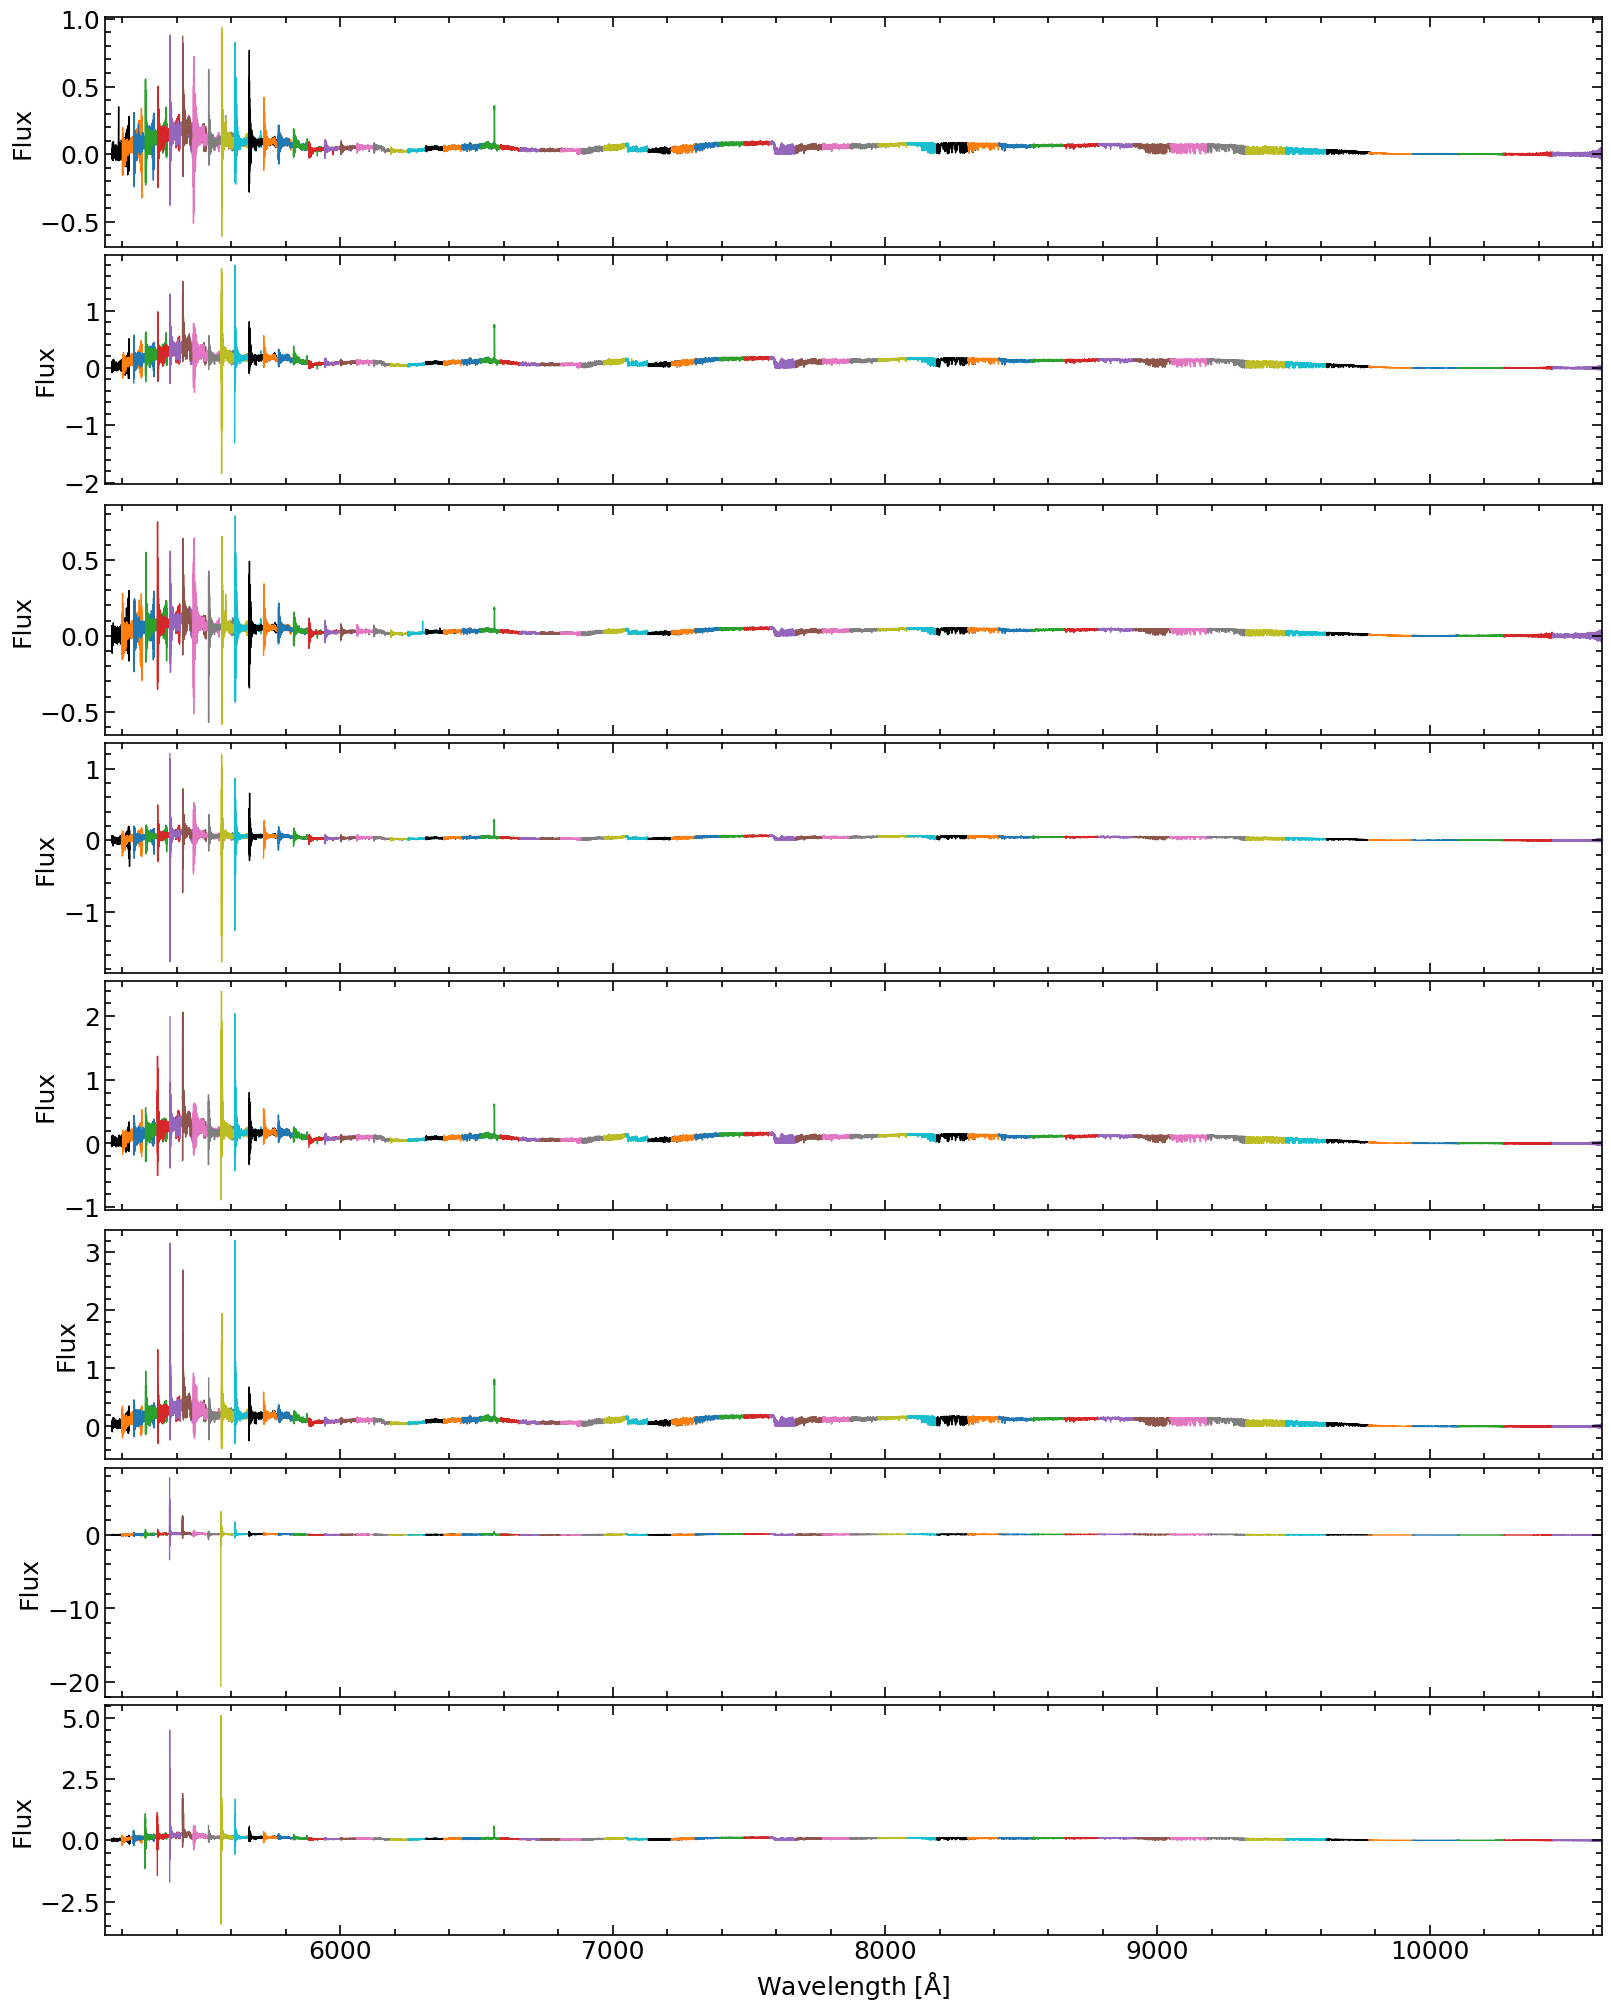

(None, None)

In [13]:
fig, ax = plt.subplots(len(lisspec.lisfil), 1, figsize=(16, 2.5*len(lisspec.lisfil)), constrained_layout=True, sharex=True)
for i in range(len(lisspec.lisfil)):
    lisspec.lisspec[i].plot_spectrum(ax=ax[i], xlabel='')
ax[-1].set(xlabel='Wavelength $[\mathrm{\AA}]$')
plt.show(), plt.close()

The bluest orders are very noisy. Let's repeat the plot without them to see the rest of spectrum better:

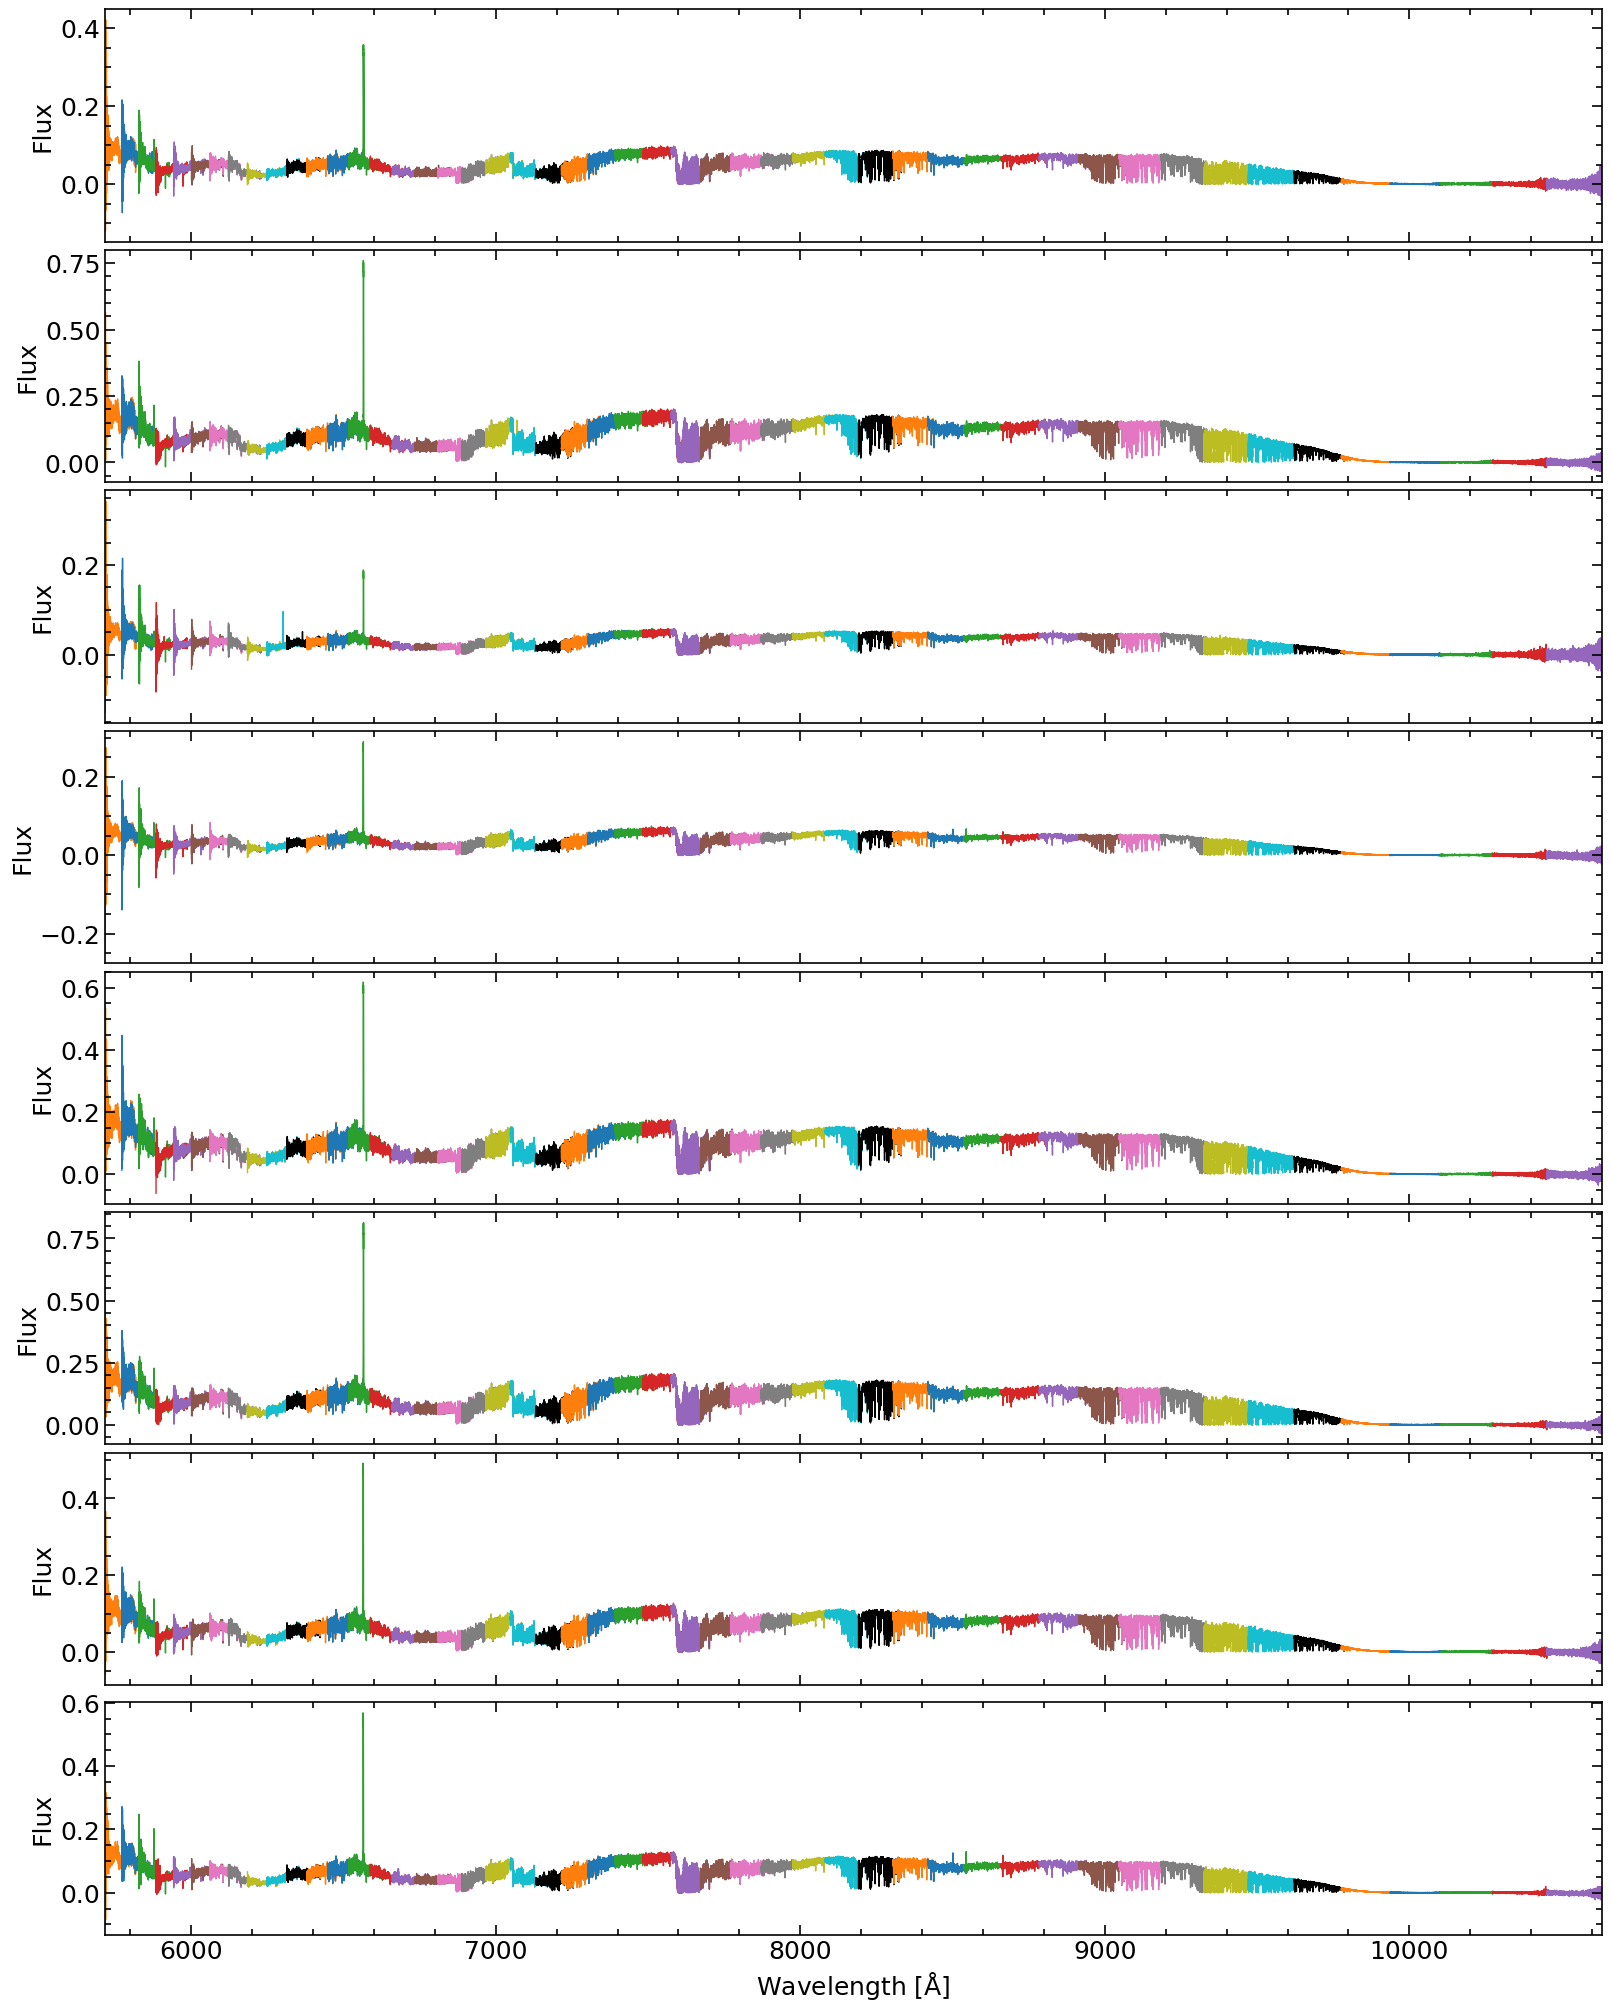

(None, None)

In [14]:
fig, ax = plt.subplots(len(lisspec.lisfil), 1, figsize=(16, 2.5*len(lisspec.lisfil)), constrained_layout=True, sharex=True)
for i in range(len(lisspec.lisfil)):
    lisspec.lisspec[i].plot_spectrum(ax=ax[i], ords=np.arange(12, 61), xlabel='')
ax[-1].set(xlabel='Wavelength $[\mathrm{\AA}]$')
plt.show(), plt.close()

### Plot some properties

In [15]:
# TODO

## Binary mask

### Read

We can load a binary mask with the `crosscorr.Model` class. It needs the file path.

In [16]:
filmask = '/Users/marina/work/code/raccoon/raccoon/data/mask/CARM_VIS/J07274+052serval_tellbervmax_fwhm2.00-30.00_contrminmin0.06_depthwq0.60_contrastmeanfwhm-1.mas'
mask = crosscorr.Model(filmask, modeltype='mask', tag='defaut_J07274+052serval',  dirout=dirout)

# Model object attributes
# vars(mask)  # print attribute name and value
mask.__dict__.keys()  # print attribute name

dict_keys(['filin', 'modeltype', 'maskformatharp', 'maskair', 'tag', 'utag', 'dirout', 'nord', 'datamod'])

### Plot

We can easily plot the mask with the method `fig_mask`:

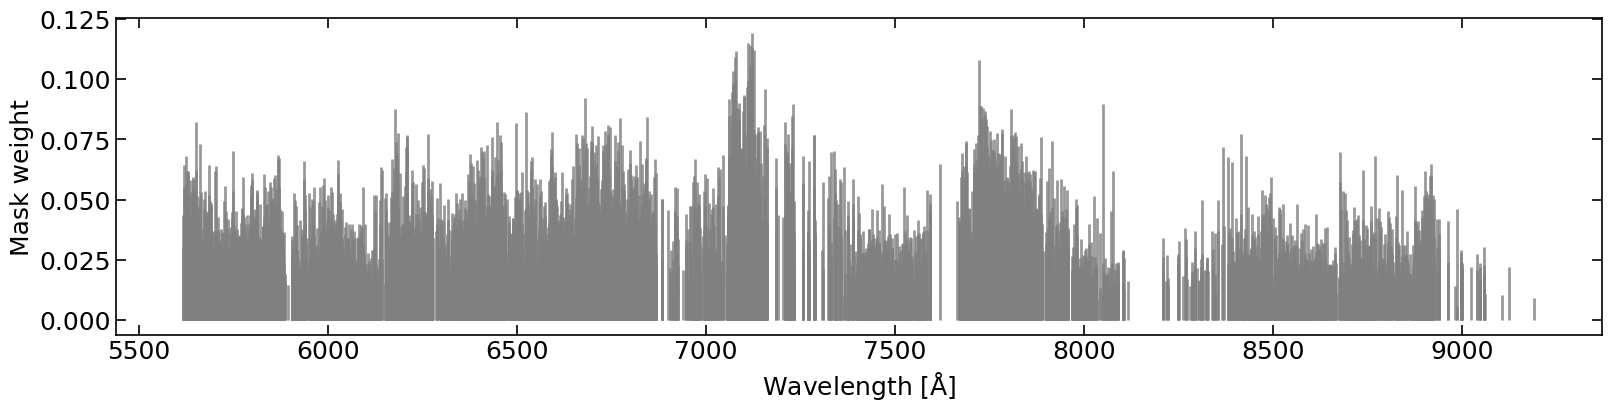

In [17]:
mask.fig_mask(sh=True, sv=False)

## Telluric mask

### Read

We are also going to load a telluric mask, to know which areas in the observed spectra are affected by telluric absortion. We can do that with the class `telluricutils.Mask`:

In [18]:
filtell = '/Users/marina/work/code/raccoon/raccoon/data/tellurics/CARM_VIS/telluric_mask_carm_short.dat'
tellmask0 = telluricutils.Mask(filin=filtell, dirout=dirout, diroutplot=dirout)

# Mask object attributes
# vars(tellmask0)  # print attribute name and value
tellmask0.__dict__.keys()  # print attribute name

Join overlap between lines


dict_keys(['filin', 'dirout', 'diroutplot', 'verbose', 'tag', 'utag', 'join_overlap', 'broaden_dv', 'w', 'f', 'w1', 'w2', 'Mask'])

Before reading the telluric mask, it is useful to first decide by how much to broaden the telluric lines. This is important if you need to compute the CCF of several observations taken at different times, because the telluric and stellar lines will overlap at different positions depending on when the observations were taken. In particular, this mainly depends on the barycentric Earth RV (BERV).

The `Spectra` object has a list of the RVs of all the observations in the attribute `dataheader`, as well as the minimum, maximum, and absolute maximum of all observations:

In [19]:
print(f'BERV min {lisspec.bervminobs} km/s')
print(f'BERV max {lisspec.bervmaxobs} km/s')
print(f'BERV abs max {lisspec.bervabsmaxobs} km/s')

BERV min -28.345505 km/s
BERV max 9.40748 km/s
BERV abs max 28.345505 km/s


To avoid any tellurics, we can broaden the telluric mask lines the maximum absolute BERV when reading it with `broaden_dv` (note this is in m/s):

In [20]:
tellmask = telluricutils.Mask(filin=filtell, broaden_dv=lisspec.bervabsmaxobs*1.e3, dirout=dirout, diroutplot=dirout)

Broaden mask by 28345.505 m/s
Join overlap between lines


### Plot

We can also easily plot it with the `fig_mask` method:

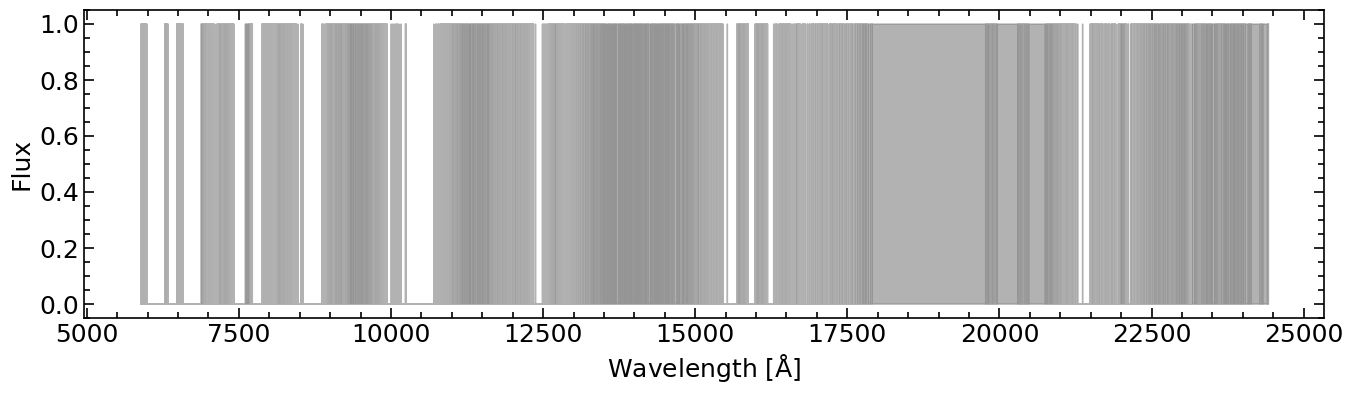

In [21]:
# Plot telluric mask
tellmask0.fig_mask(sh=True, sv=False)

We can compare the telluric mask with and without broadening the lines:

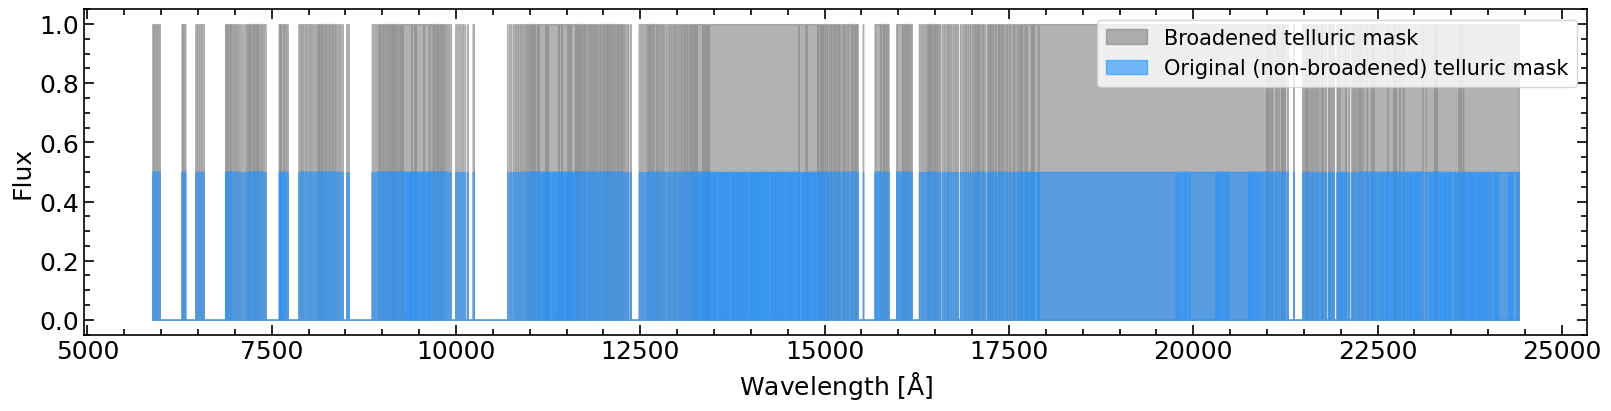

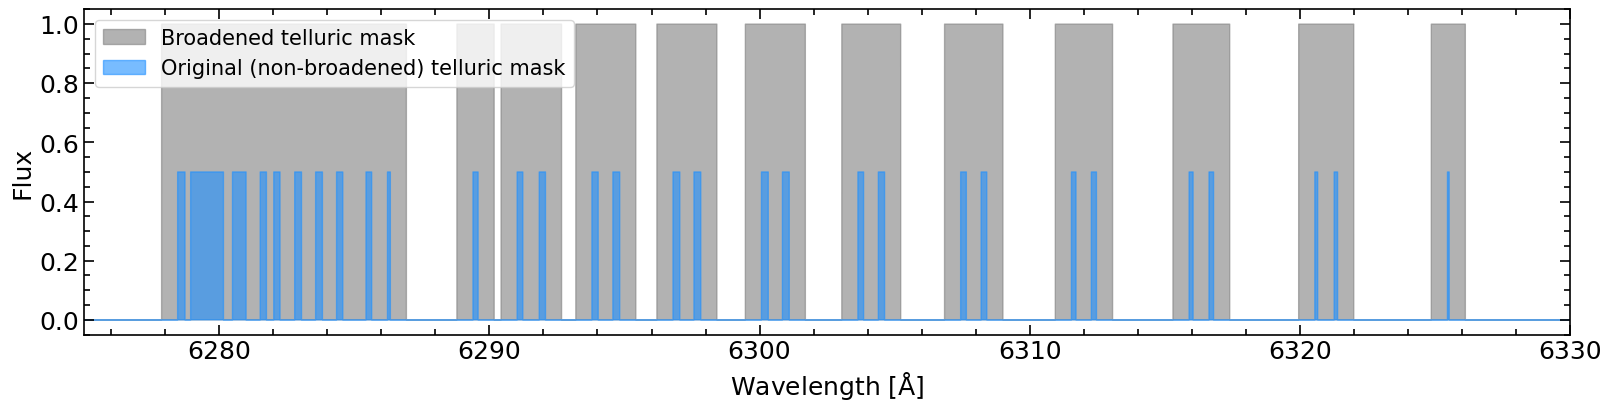

(None, None)

In [22]:
# Plot telluric mask
fig, ax = plt.subplots(1, 1, figsize=(16, 4), constrained_layout=True)
tellmask.plot_mask(ax=ax, zorder=-1, leglabel='Broadened telluric mask')
tellmask0.plot_mask(ax=ax, fscale=0.5, zorder=-1, color='dodgerblue', leglabel='Original (non-broadened) telluric mask')
ax.legend(fontsize='small')
plt.show(), plt.close()

# Zoom in to see line differences
fig, ax = plt.subplots(1, 1, figsize=(16, 4), constrained_layout=True)
tellmask.plot_mask(ax=ax, zorder=-1, leglabel='Broadened telluric mask')
tellmask0.plot_mask(ax=ax, fscale=0.5, zorder=-1, color='dodgerblue', leglabel='Original (non-broadened) telluric mask')
ax.legend(fontsize='small')
ax.set(xlim=(6275, 6330))
# ax.set(xlim=(6275, 6285))
plt.show(), plt.close()

## Plot all inputs

We are now going to plot the observed spectra, binary mask, and telluric mask, all together:

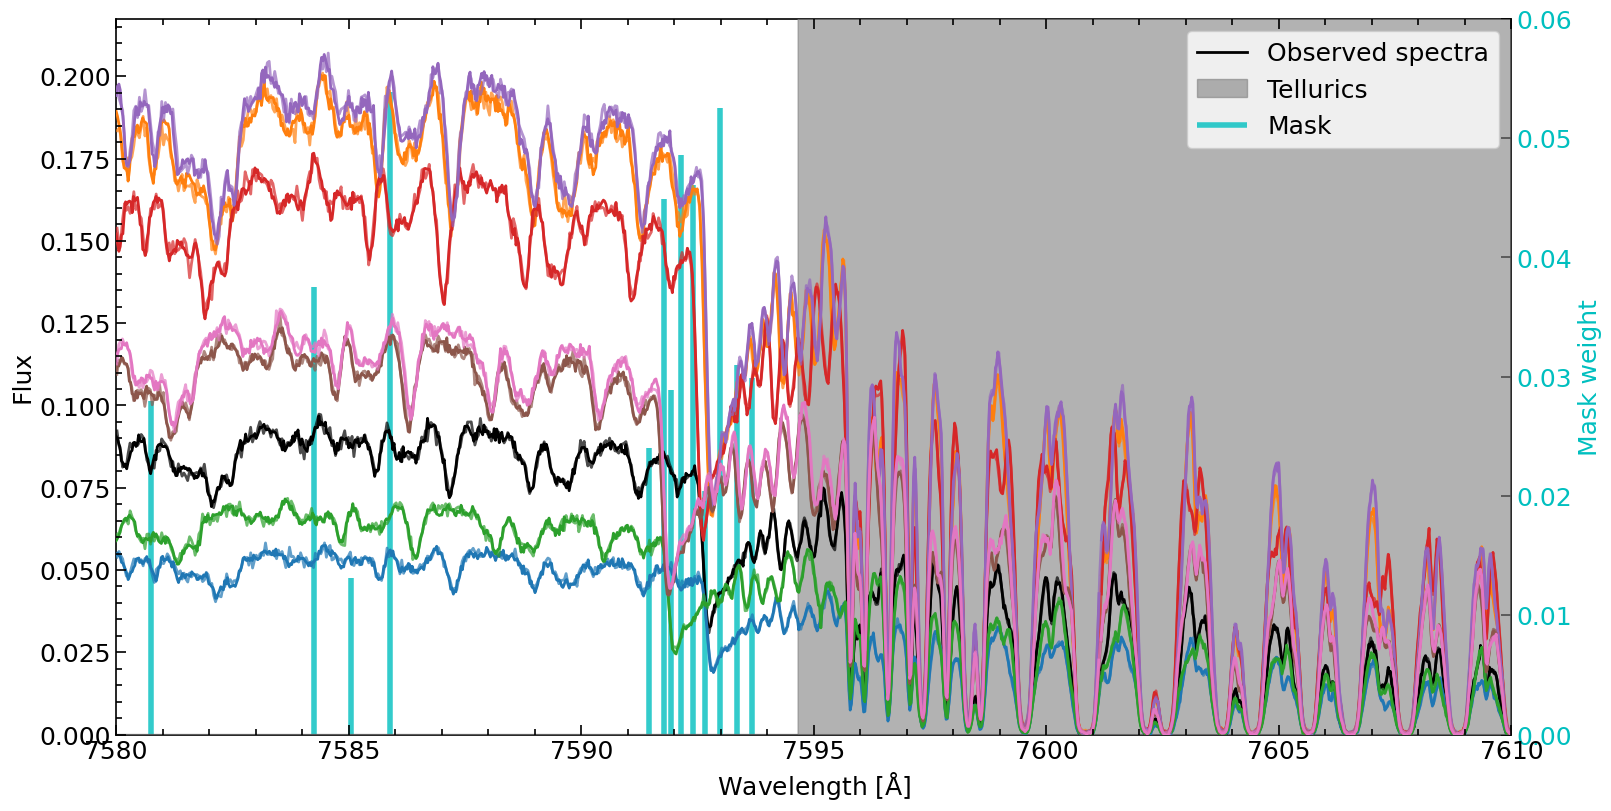

(None, None)

In [23]:
fig, ax = plt.subplots(1, 1, figsize=(16, 8), constrained_layout=True)
# Spectrum
ax = lisspec.plot_spectra(ax=ax, wmin=7580, wmax=7610, lw=2, legendwhich='first', legendlabel='Observed spectra')
ylim = ax.get_ylim()

# # Binary mask
# ax = mask.plot_mask(ax=ax, ymin=ylim[0], yscale=2, linewidths=4, color='c')
# Binary mask in new axis
ax2 = ax.twinx()  # instantiate a second Axes that shares the same x-axis
ax2 = mask.plot_mask(ax=ax2, ymin=0, linewidths=4, color='c', keeplims=False, zorder=-2, leglabel='Mask')
ax2.tick_params(axis='y', labelcolor='c')
ax2.set_ylabel('Mask weight', color='c')
ax2.set_ylim(0, 0.06)

# Telluric mask
ax = tellmask.plot_mask(ax=ax, fscale=ylim[1], zorder=-3, leglabel='Tellurics')

# Format
ax.set_zorder(ax2.get_zorder()+1)
ax.set_frame_on(False)
ax.set_ylim(0, ylim[1])
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2)
plt.show(), plt.close()

We can also plot each observation colour-coded as a function of e.g. its BERV:

/Users/marina/anaconda3/envs/raccoon/lib/python3.11/site-packages/popurri/spectrum.py:1178: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  norm = mpl.colors.Normalize(vmin=np.nanmin(cprop[lisspec]), vmax=np.nanmax(cprop[lisspec]))
/Users/marina/anaconda3/envs/raccoon/lib/python3.11/site-packages/popurri/spectrum.py:1211: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  c = cmap(norm(cprop[idx]))


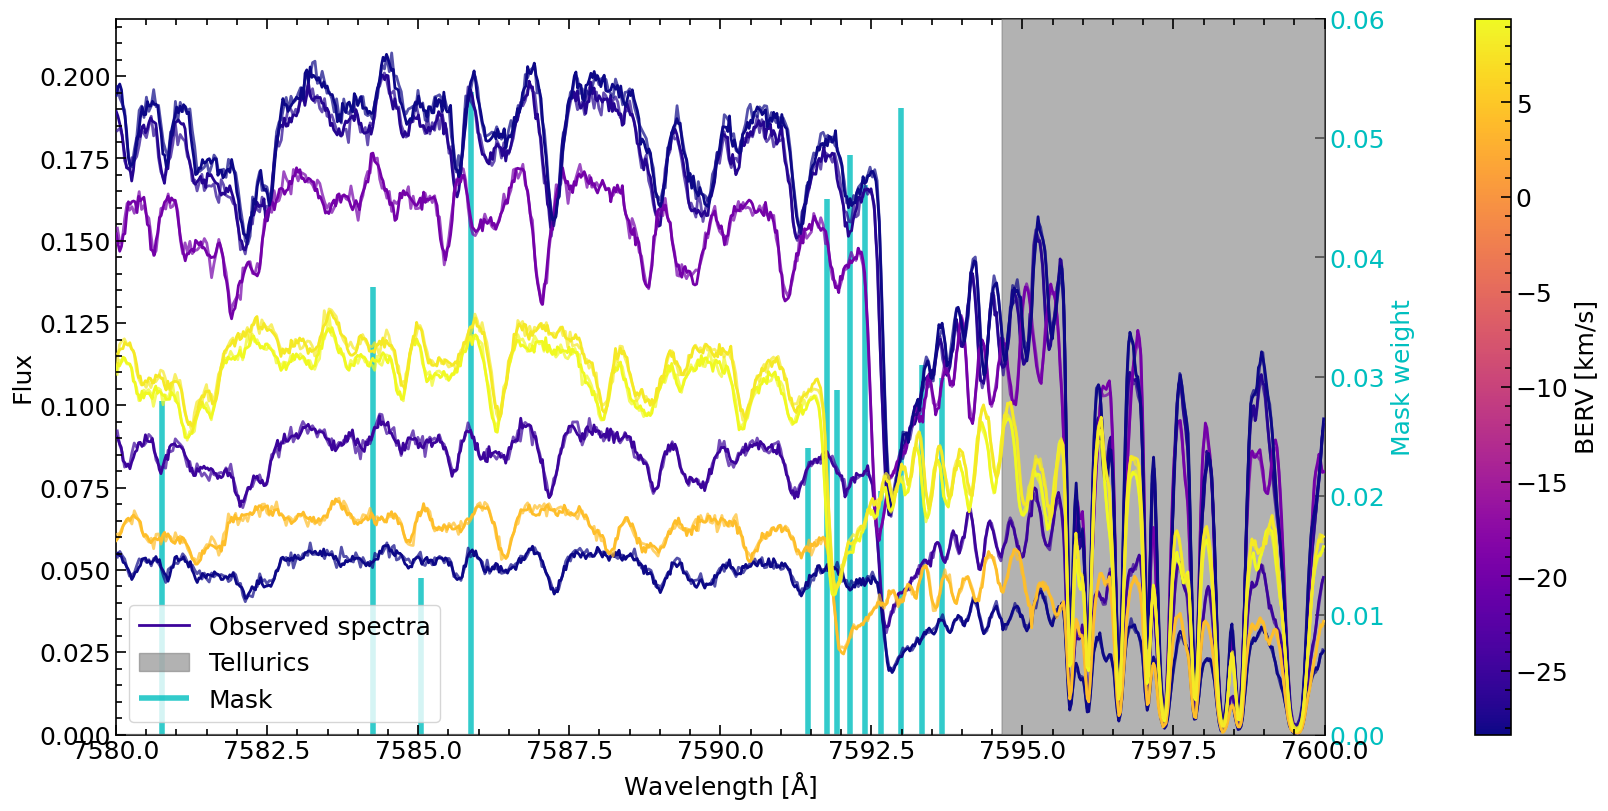

(None, None)

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(16, 8), constrained_layout=True)
# Spectrum
ax = lisspec.plot_spectra(ax=ax, wmin=7580, wmax=7600, lw=2, legendwhich='first', legendlabel='Observed spectra', cprop=lisspec.dataheader['berv'], cbarlabel='BERV [km/s]', cmap='plasma')
ylim = ax.get_ylim()

# # Binary mask
# ax = mask.plot_mask(ax=ax, ymin=ylim[0], yscale=2, linewidths=4, color='c')
# Binary mask in new axis
ax2 = ax.twinx()  # instantiate a second Axes that shares the same x-axis
ax2 = mask.plot_mask(ax=ax2, ymin=0, linewidths=4, color='c', keeplims=False, zorder=-2, leglabel='Mask')
ax2.tick_params(axis='y', labelcolor='c')
ax2.set_ylabel('Mask weight', color='c')
ax2.set_ylim(0, 0.06)

# Telluric mask
ax = tellmask.plot_mask(ax=ax, fscale=ylim[1], zorder=-3, leglabel='Tellurics')

# Format
ax.set_zorder(ax2.get_zorder()+1)
ax.set_frame_on(False)
ax.set_ylim(0, ylim[1])
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2)
plt.show(), plt.close()

## Apply BERV correction

As you can see in the plot above, the observations are given in the observer's rest frame, so all the telluric lines of different observations are "aligned" (because they always fall on the same pixel on the detector).

The stellar lines of different observations are not aligned with each other. We can Doppler shift each observation by its BERV and repeat the plot. Now the stellar lines of different observations will be aligned with each other (and the telluric lines will not be).

In [25]:
# TODO prepare lisv
lisspec.dataheader['berv'] # ?????
# Add instrumental drift

lisv = lisspec.dataheader['berv'] * 1.e3  # km/s to m/s

# Apply Doppler shift to the wavelength dataspec['w']
# The shifted wavelength is saved in dataspec['wshift']
lisspec.dopplershift(lisv) # Inputs are in m/s

/Users/marina/anaconda3/envs/raccoon/lib/python3.11/site-packages/popurri/spectrum.py:1089: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  v = lisv[i]


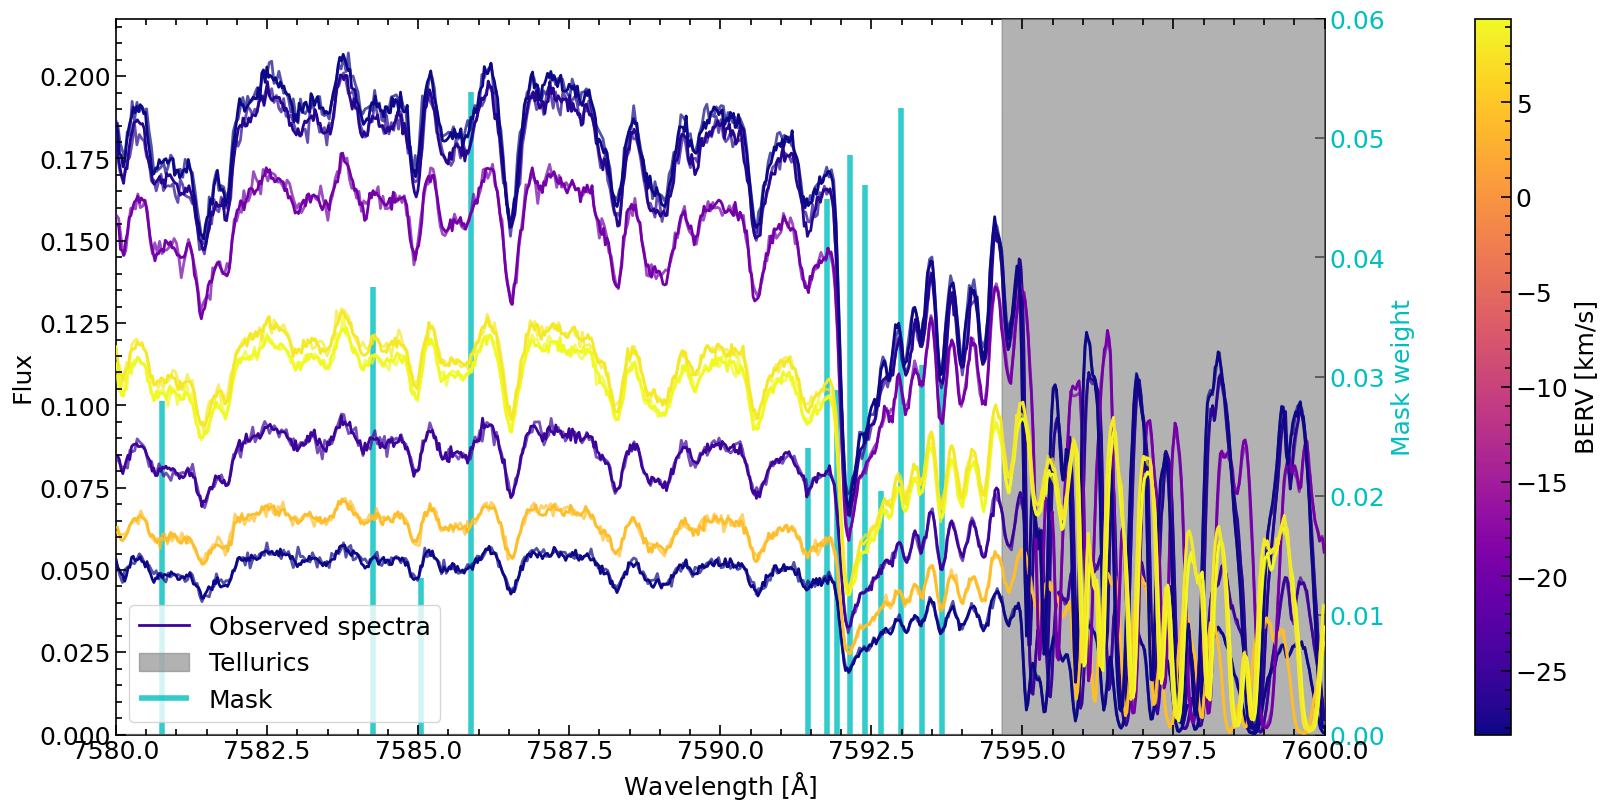

(None, None)

In [26]:
fig, ax = plt.subplots(1, 1, figsize=(16, 8), constrained_layout=True)
# Spectrum
ax = lisspec.plot_spectra(ax=ax, x='wshift', wmin=7580, wmax=7600, lw=2, legendwhich='first', legendlabel='Observed spectra', cprop=lisspec.dataheader['berv'], cbarlabel='BERV [km/s]', cmap='plasma')
ylim = ax.get_ylim()

# # Binary mask
# ax = mask.plot_mask(ax=ax, ymin=ylim[0], yscale=2, linewidths=4, color='c')
# Binary mask in new axis
ax2 = ax.twinx()  # instantiate a second Axes that shares the same x-axis
ax2 = mask.plot_mask(ax=ax2, ymin=0, linewidths=4, color='c', keeplims=False, zorder=-2, leglabel='Mask')
ax2.tick_params(axis='y', labelcolor='c')
ax2.set_ylabel('Mask weight', color='c')
ax2.set_ylim(0, 0.06)

# Telluric mask
ax = tellmask.plot_mask(ax=ax, fscale=ylim[1], zorder=-3, leglabel='Tellurics')

# Format
ax.set_zorder(ax2.get_zorder()+1)
ax.set_frame_on(False)
ax.set_ylim(0, ylim[1])
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2)
plt.show(), plt.close()

Note that the mask lines are not really aligned with the stellar lines. This is because the mask is at radial velocity of 0, while the stellar lines are shifted by the average systemic velocity of the star with respect to us, which can be of a few km/s. Any shifts of the order of the m/s caused by e.g. a planetary companion are too small to be seen on the spectral lines from a plot like this.

We can now Doppler-shift all the observations by the systemic velocity of the star to align the stellar lines with the mask lines.

In [27]:
# Systemic velocity for the star YZ CMi https://simbad.u-strasbg.fr/simbad/sim-basic?Ident=yz+cmi&submit=SIMBAD+search
vsys = 26.66  # km/s



# def dopplershift(self, lisv, rel=True, x='w', xnew='wshift'):
#     C_MS = 2.99792458*1.e8  # Light speed [m/s]
#     # Make sure `lisv` is a list, and set it to same value for all obs
#     if not np.issubdtype(type(lisv), list):
#         lisv = [lisv] * self.nobs
#     # Make sure `lisv` has the same length as the number of obs
#     if len(lisv) != self.nobs:
#         raise ValueError('`lisv` must have the same length as the number of observations')
    
#     liswshift = []
#     # for i, k in enumerate(self.dataspec.keys()):
#     for i, k in enumerate(self.lisfilname):
#         # spec = self.lisspec[i]  # only works is deleteindividual=False
#         w = self.dataspec[x][i]
#         v = lisv[i]
#         if rel: a = np.sqrt((1 + v / C_MS) / (1 - v / C_MS))
#         else: a = (1 - v / C_MS)
#         # wshift = np.ones_like(spec.dataspec[x]) * np.nan
#         wshift = np.ones_like(w) * np.nan
#         for o in self.ords:
#             # wshift[o] = spec.dataspec[x][o] * a
#             wshift[o] = w[o] * a
#         # self.dataspec[k].dataspec[xnew] = wshift
#         liswshift.append(wshift)
#     self.dataspec[xnew] = np.array(liswshift)
#     # TODO add to self.lisspec if deleteindividual is False
#     return
# dopplershift(lisspec, -vsys * 1.e3, x='wshift', xnew='wshift_berv_vsys') # Inputs are in m/s



# Apply Doppler shift to the BERV-corrected wavelength dataspec['wshift']
# The shifted wavelength is saved in dataspec['wshift_berv_vsys']
lisspec.dopplershift(-vsys * 1.e3, x='wshift', xnew='wshift_berv_vsys') # Inputs are in m/s

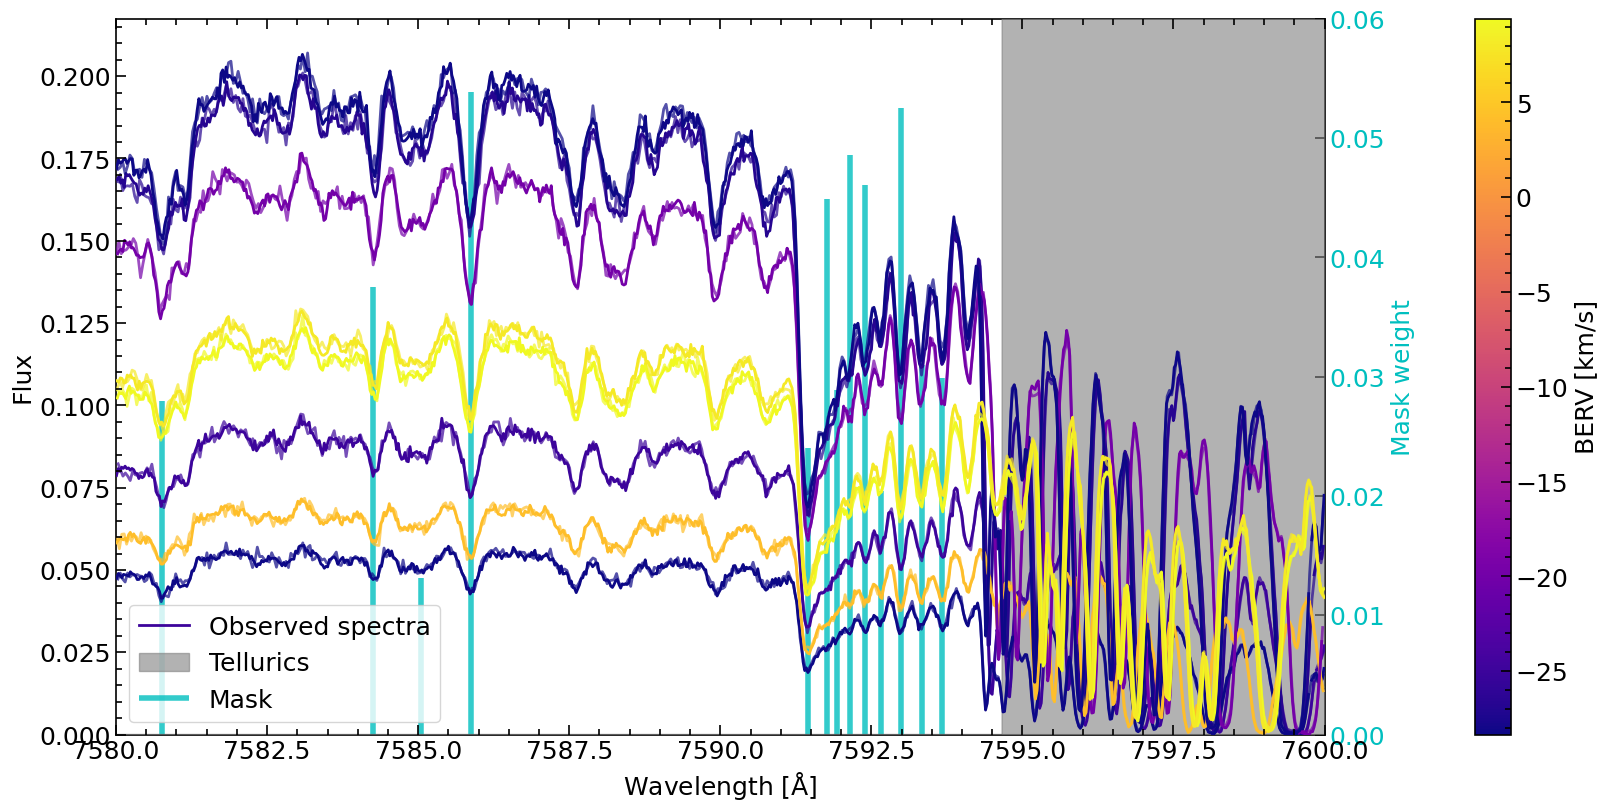

(None, None)

In [28]:
# Plot
fig, ax = plt.subplots(1, 1, figsize=(16, 8), constrained_layout=True)
# Spectrum
ax = lisspec.plot_spectra(ax=ax, x='wshift_berv_vsys', wmin=7580, wmax=7600, lw=2, legendwhich='first', legendlabel='Observed spectra', cprop=lisspec.dataheader['berv'], cbarlabel='BERV [km/s]', cmap='plasma')
ylim = ax.get_ylim()

# # Binary mask
# ax = mask.plot_mask(ax=ax, ymin=ylim[0], yscale=2, linewidths=4, color='c')
# Binary mask in new axis
ax2 = ax.twinx()  # instantiate a second Axes that shares the same x-axis
ax2 = mask.plot_mask(ax=ax2, ymin=0, linewidths=4, color='c', keeplims=False, zorder=-2, leglabel='Mask')
ax2.tick_params(axis='y', labelcolor='c')
ax2.set_ylabel('Mask weight', color='c')
ax2.set_ylim(0, 0.06)

# Telluric mask
ax = tellmask.plot_mask(ax=ax, fscale=ylim[1], zorder=-3, leglabel='Tellurics')

# Format
ax.set_zorder(ax2.get_zorder()+1)
ax.set_frame_on(False)
ax.set_ylim(0, ylim[1])
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2)
plt.show(), plt.close()

## Compute CCF

### Initialise

Initialise the CCF object `crosscorr.Crosscorr` by passing the observed spectra, binary mask, and optionally the telluric mask we loaded above.

In [29]:
# Prepare CCF inputs

# Prepare cross-correlation object
ccf = crosscorr.Crosscorr(lisspec, mask, tellmask=tellmask, dirout=dirout)

# Crosscorr object attributes
# vars(ccf)  # print attribute name and value
ccf.__dict__.keys()  # print attribute name

dict_keys(['data', 'model', 'tellmask', 'ords_use', 'tag', 'dirout', 'verbose', 'test_run', 'test_rvcen', 'test_rvrng', 'test_rvstp', 'test_o', 'test_dmin', 'test_rv', 'test_ccf', 'test_rvcen_result', 'test_rvrng_result', 'test_fitpar', 'test_rv_new', 'rvcen', 'rvrng', 'rvstp', 'rvstpreal', 'rvgrid', 'rvgridreal', 'fitfunc', 'fitrng', 'fitrngeach', 'fluxratiotype', 'fluxratio', 'nlinmin', 'obs_ref', 'iobs_ref'])

### Initial test CCF

Compute an initial "test" CCF to locate the CCF minimum. This "test" computes the CCF of the reference order of the reference observation over a wide RV range in coarse steps. This is done if we do not know the systemic velocity of the observed star, or if the star is a fast rotator. This is because:
- If the systemic velocity is high, a CCF computed over a narrow RV range centred at 0 might miss the CCF minimum.
- If the star rotates fast, the CCF minimum will be wide. Then, the RV range needs to be large enough to cover the whole CCF.
From this test CCF, we can then determine a good RV range.

Computing initial test CCF with RV center 0.0, RV range +- 200.0, and RV step 1.0, on order 36 of observation car-20170412T20h02m25s-sci-gtoc-vis_A
  RV cen: 25.0 km/s
  RV range: 30 km/s (FWHM 9.733761348398922, chi2red 1.112676048919212e-19)


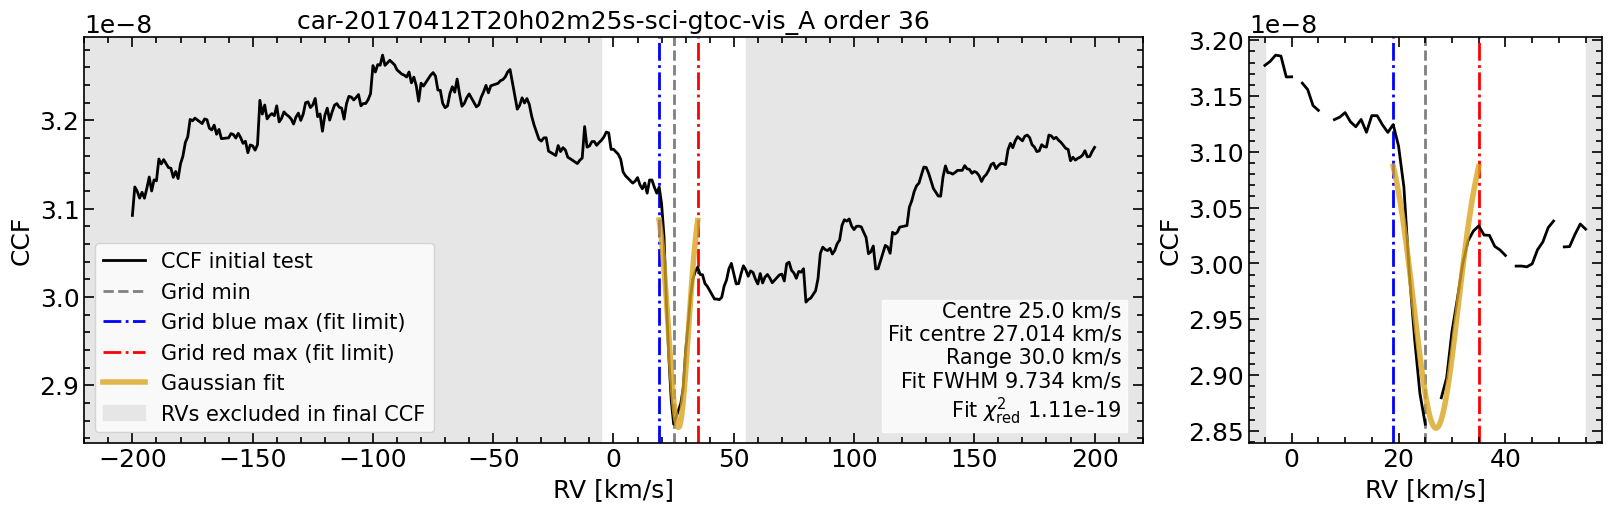

In [30]:
ccf.computeccf_initial_test(x='wshift')

We can finally "set" the RV centre and range of the "final" CCF grid with `set_rvgrid_from_initial_test`:

In [31]:
ccf.set_rvgrid_from_initial_test()

RV range and centre set from initial test CCF
RV grid set
  RV centre 25.0
  RV range 30
  RV step 1.258
  RV step real 1.258
  RV grid length 49
  RV grid real length 49


If we know the systemic velocity of the star and have an idea of its rotation velocity, we can skip the CCF test and directly define an RV range with `ccf.rvcen` and `ccf.rvrng`. `ccf.rvcen` should be centred at the systemic velocity of the star, and `ccf.rvrng` should be wide enough to cover the whole CCF minimum.

We can set the RV grid with `set_rvgrid()`:
```python
ccf.set_rvgrid(rvcen=10, rvrng=25)
```
Note that this is not necessary if `set_rvgrid_from_initial_test` has already been run.

As RV step `ccf.rvstp`, we use by default the velocity pixel sampling of the spectrograph. This makes sure that we are using the right amount of photons (the mask lines are going to have a width of 1 pixel). With a step wider than 1 pixel (in velocity space), we would miss pixels, i.e., photons, and with a step narrower than 1 pixel, we would count the same photons more than ones, artificially increasing the S/N, which would lead to underestimated RV uncertainties.

Sometimes it might be useful to oversample the CCF, e.g., to get a well sampled bisector. On those cases, we can set a smaller RV grid in `ccf.rvstp`, and the default step will be stored on `ccf.rvstpreal`. In that case, two CCFs will be computed for each observation, one with step `ccf.rvstp` (oversampled) and the other on with `ccf.rvstpreal` (real step). The oversampled CCF will only be used to measure the bisector, while the "real sample" CCF will be used to obtain uncertanties (since uncertainties would be underestimated in the oversampled CCF).
The custom RV step can be specified in `set_rvgrid` with the parameter `rvstp`.
The "real" RV step can also be changed in `set_rvgrid` with the parameter `rvstpreal`, but this is not recommended.

### Prepare flux 

In [32]:
# Compute order flux ratios
ccf.compute_ord_fluxratio(fluxratiotype='obshighsnr', save=True)

Computing flux ratios per order, with fluxratiotype: obshighsnr
Flux ratios per order saved in ./ccf_guide/J07446+035.fluxratio.csv


### Prepare wavelength

### Prepare telluric mask

If not done when loading the telluric mask, we can select by which value we want to broaden the telluric mask lines with `broaden_tellmask_value`. The default is to not broaden. Options are:
- Broaden by a specific value, which is selected with `vbroadtype='value'` and `vbroad=VAL`, in km/s.
- Broaden by the maximum absolute(BERV) of the observations, which is selected with `vbroadtype='bervabsmaxobs'`

```python
ccf.broaden_tellmask_value(vbroadtype='bervabsmaxobs')
# Warning: Telluric mask already broadened when initialised, by 28345.505 m/s
# Telluric mask to be broadened by 28.346 km/s (vbroadtype: bervabsmaxobs)
```

We are going to be removing model (mask) lines that overlap with telluric lines. To avoid interpolation issues, we can extend the telluric mask to cover the wavelength range of all the data and the model (mask):

In [ ]:
# Extend tell mask
print(self.tellmask.w)
self.extend_tellMask()
print(self.tellmask.w)

### Prepare binary mask

In [89]:
print(ccf.model.__dict__)
# Cut mask to selected wavelength range to be used
wmin = 5200
wmax = 9600
self = ccf
m = (self.model.datamod['wm'] >= wmin) & (self.model.datamod['wm'] <= wmax)
self.model.datamod['wm'] = self.model.datamod['wm'][m]
self.model.datamod['fm'] = self.model.datamod['fm'][m]
self.model.datamod['nlin'] = len(self.model.datamod['wm'])
print(self.model.datamod['nlin'])



# Select mask lines free of tellurics
# self = ccf
C_KMS = 299792.458  # Speed of light [km/s]
rvnew = self.rvgrid
mask = [[]] * len(rvnew)
for i, maskshift in enumerate(rvnew):
    wm_shift = self.model.datamod['wm'] * (1 + maskshift / C_KMS)

    # Flag lines in bad regions: False in bad region, True otherwise
    mask[i] = np.array(self.tellmask.Mask(wm_shift), dtype=bool)

# Join masks for each RV shift
maskjoin = np.prod(mask, axis=0, dtype=bool)

# # Plot: Check mask join is OK
# for i in range(len(mask)):
#     plt.plot(np.arange(len(mask[0])), mask[i], 'o')
# plt.plot(np.arange(len(mask[0])), maskjoin, '+', ms=10)
# plt.show()
# plt.close()

# Remove lines in telluric regions
wm = self.model.datamod['wm'][maskjoin]
fm = self.model.datamod['fm'][maskjoin]

nlin = len(wm)

# Select mask lines per order usable at any epoch

# Remove orders with not enough lines

{'filin': '/Users/marina/work/code/raccoon/raccoon/data/mask/CARM_VIS/J07274+052serval_tellbervmax_fwhm2.00-30.00_contrminmin0.06_depthwq0.60_contrastmeanfwhm-1.mas', 'modeltype': 'mask', 'maskformatharp': False, 'maskair': False, 'tag': 'defaut_J07274+052serval', 'utag': '_defaut_J07274+052serval', 'dirout': './ccf_guide/', 'nord': 1, 'datamod': {'wm': array([5617.81580789, 5617.93335304, 5618.68666915, ..., 8598.07508562,
       8599.33299352, 8599.74823589]), 'fm': array([0.03050047, 0.04363222, 0.02774236, ..., 0.01785539, 0.02942812,
       0.01508726]), 'nlin': 4984, 'ords': array([0]), 'nord': 1}, 'nlin': 4984}
4984
[ 5885.4565      5884.91962572  5886.15028541 ... 24415.54028152
 24411.24868775 24411.32868019]
[ 4636.50512892  5885.4565      5884.91962572 ... 24411.24868775
 24411.32868019 24911.32868019]


ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

Compute CCF of all observations, order-by-order.

In [16]:
# Compute CCF

In [17]:
# Plot CCF